### 0. Virtual Environment Checking

In [3]:
import sys

def is_colab() -> bool:
    """Check if the current runtime environment is Google Colab."""
    if "google.colab" in sys.modules:
        return True
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Diagnostics
in_colab = is_colab()
in_venv = sys.prefix != sys.base_prefix

print(f"Google Colab : {in_colab}")
print(f"Virtual Env  : {in_venv}")
print(f"Python Path  : {sys.executable}")


Google Colab : True
Virtual Env  : False
Python Path  : /usr/bin/python3


# 1. Classification Dataset

### 1.1. Generate Classification Dataset

In [4]:
from sklearn.datasets import make_circles

n_samples = 1000 # number of samples

X, y = make_circles(n_samples, noise=0.03, random_state=42)

print(f"Dataset Features (X)")
for i in range(5):
    print(f"X[{i}]: {X[i]}")

print(f"\nDataset Labels (y)")
for i in range(5):
    print(f"y[{i}]: {y[i]}")


Dataset Features (X)
X[0]: [0.75424625 0.23148074]
X[1]: [-0.75615888  0.15325888]
X[2]: [-0.81539193  0.17328203]
X[3]: [-0.39373073  0.69288277]
X[4]: [ 0.44220765 -0.89672343]

Dataset Labels (y)
y[0]: 1
y[1]: 1
y[2]: 1
y[3]: 1
y[4]: 0


### 1.2. Visualize Classification Datasets

In [5]:
import pandas as pd

circles = pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "label": y})

circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


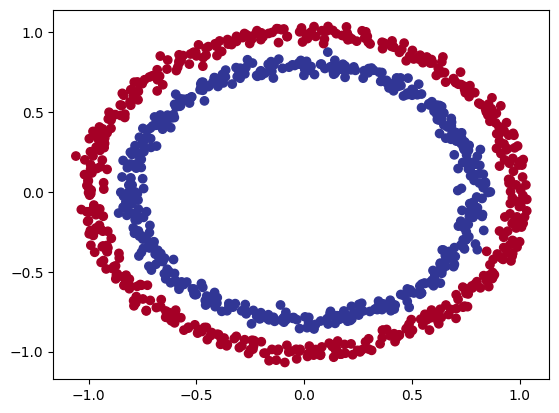

In [6]:
import matplotlib.pyplot as plt

plt.scatter(x=X[:, 0], y=X[:, 1], c=y, cmap=plt.cm.RdYlBu);

### 1.3. Classification Dataset Labels

In [7]:
# My Code
# counter_label_0 = circles.label.value_counts()[0]
# counter_label_1 = circles.label.value_counts()[1]

# if counter_label_0 == counter_label_1:
#     print("The Dataset is BALANCED!!!")
# else:
#     print("The Dataset is UNBALANCED!!!")

# Gemini Code
counts = circles['label'].value_counts()
imbalance_ratio = counts.min() / counts.max()

# Considered balanced if the smaller class is at least 90% of the larger class
if imbalance_ratio >= 0.90:
    print(f"The Dataset is BALANCED (ratio: {imbalance_ratio:.2f})")
else:
    print(f"The Dataset is UNBALANCED (ratio: {imbalance_ratio:.2f})")


The Dataset is BALANCED (ratio: 1.00)


### 1.4. Classification Dataset Input and Output Shapes

In [8]:
X.shape, y.shape

((1000, 2), (1000,))

### 1.5. Turn Data into Tensors

In [9]:
import torch

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

### 1.6. Split Dataset into Training and Testing Datasets

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train: {len(X_train)} samples")
print(f"X_test: {len(X_test)} samples")
print(f"y_train: {len(y_train)} samples")
print(f"y_test: {len(y_test)} samples")

X_train: 800 samples
X_test: 200 samples
y_train: 800 samples
y_test: 200 samples


# 2. Building a Classification Model

### 2.1. Importing Standard PyTorch Libraries

In [11]:
import torch
from torch import nn

### 2.2. Setting up a Device Agnostic Environment

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Current Device: {device}")

Current Device: cpu


### 2.3. Building CircleModelV0

In [13]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        # first layer
        self.layer_1 = nn.Linear(in_features=2, out_features=5)

        # second layer
        self.layer_2 = nn.Linear(in_features=5, out_features=1)

    def forward(self, x):
        return self.layer_2(self.layer_1(x))

# an instance of the model (good practice: send it to target device)
model_0 = CircleModelV0().to(device)

print("model_0 details")
model_0


model_0 details


CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

### 2.4. Untrained CircleModelV0 Inference

In [14]:
# Make predictions with the model
untrained_preds = model_0(X_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[ 0.0521],
        [-0.1132],
        [ 0.3456],
        [-0.0305],
        [ 0.1238],
        [ 0.0247],
        [-0.2649],
        [-0.2332],
        [ 0.3545],
        [-0.1267]], grad_fn=<SliceBackward0>)

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


### 2.5. Loss Function and Optimizer Setup

In [23]:
from sympy.core import parameters
# loss_fn = nn.BCELoss() # no sigmoid built-ina
loss_fn = nn.BCEWithLogitsLoss() # sigmoid built-in

optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

# IMPORTANT: Never do a commit at 12:30 A.M.

### **Note: I somehow deleted a lot of the code that I wrote for a couple of hours. :)**
###       I made a commit. After doing that commit, I added one extra comment only for testing.
###       I then pressed 'Ctrl + S' (Save), thinking that all the code that I wrote for a couple of hours
###       was already saved and also posted on GitHub. Apparently, this was not the case. :)
###       I think what happened is that only a part of the code that I wrote was saved and also posted on GitHub.
###       And when I pressed 'Ctrl + S' all the rest was saved, including that dummy message that I wrote.

# **NEVER DISCARD ANY CHAGES WITHOUT DOUBLE CHECKING THAT YOU ALREADY HAVE ALL THE CODE THAT YOU WROTE**

### 2.6. Accuracy Function

In [16]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    acc = (correct / len(y_pred)) * 100
    return acc

# 3. Train and Test Model

### IMPORTANT
* Odds and Log(Odds): https://youtu.be/ARfXDSkQf1Y?si=7N5lx4ElNGVNl0XJ

* Odds Ratios and Log(Odds Ratios): https://youtu.be/8nm0G-1uJzA?si=GoN5E6znCN5CLy_0

* Understanding Odds and Logits in ML: https://share.gemini.google/t7omLjPJI5GO

### 3.1. Logits (Pre-Activation Outputs)

In [17]:
y_logits = model_0(X_test.to(device))[:5]
y_logits

tensor([[ 0.0521],
        [-0.1132],
        [ 0.3456],
        [-0.0305],
        [ 0.1238]], grad_fn=<SliceBackward0>)

### 3.2. Prediction Probabilities (Post-Activation Outputs)

In [18]:
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.5130],
        [0.4717],
        [0.5855],
        [0.4924],
        [0.5309]], grad_fn=<SigmoidBackward0>)

### 3.3.  Prediction Labels (Final Result)

In [19]:
y_pred_labels = torch.round(y_pred_probs)
y_pred_labels, y_pred_labels.shape

(tensor([[1.],
         [0.],
         [1.],
         [0.],
         [1.]], grad_fn=<RoundBackward0>),
 torch.Size([5, 1]))

In [22]:
y_pred_labels.squeeze(), y_pred_labels.squeeze().shape

(tensor([1., 0., 1., 0., 1.], grad_fn=<SqueezeBackward0>), torch.Size([5]))

### 3.4. Build Training and Testing Loop

In [ ]:
torch.manual_seed(42)

# Set the number of epochs
epochs = 100

# Put data to target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Table Header
print("=" * 65)
print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Train Acc':^11} | {'Test Loss':^11} | {'Test Acc':^10}")
print("=" * 65)

# Build training and evaluation loop
for epoch in range(epochs):
    ### Training
    model_0.train()

    # 1. Forward pass (model outputs raw logits)
    y_logits = model_0(X_train).squeeze() # squeeze to remove extra `1` dimensions, this won't work unless model and data are on same device
    y_pred = torch.round(torch.sigmoid(y_logits)) # turn logits -> pred probs -> pred labls

    # 2. Calculate loss/accuracy
    # loss = loss_fn(torch.sigmoid(y_logits), # Using nn.BCELoss you need torch.sigmoid()
    #                y_train)
    loss = loss_fn(y_logits, # Using nn.BCEWithLogitsLoss works with raw logits
                   y_train)
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_0.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    
    if epoch % 10 == 0 or epoch == epochs - 1:
        print(f"{epoch:^7} | {loss:^12.5f} | {acc:^10.2f}% | {test_loss:^11.5f} | {test_acc:^9.2f}%")

 Epoch  |  Train Loss  |  Train Acc  |  Test Loss  |  Test Acc 
   0    |   0.69298    |   51.38   % |   0.69456   |   46.50  %
  10    |   0.69298    |   51.38   % |   0.69457   |   46.50  %
  20    |   0.69298    |   51.38   % |   0.69458   |   46.00  %
  30    |   0.69298    |   51.25   % |   0.69459   |   46.00  %
  40    |   0.69298    |   51.38   % |   0.69459   |   46.00  %
  50    |   0.69298    |   51.62   % |   0.69460   |   45.50  %
  60    |   0.69298    |   51.62   % |   0.69460   |   45.50  %
  70    |   0.69298    |   51.50   % |   0.69461   |   45.50  %
  80    |   0.69298    |   51.25   % |   0.69461   |   45.50  %
  90    |   0.69298    |   51.25   % |   0.69461   |   45.50  %
  99    |   0.69298    |   51.12   % |   0.69462   |   45.50  %


# 4. Make Predictions and Evaluate (CircleModelV0)

In [30]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


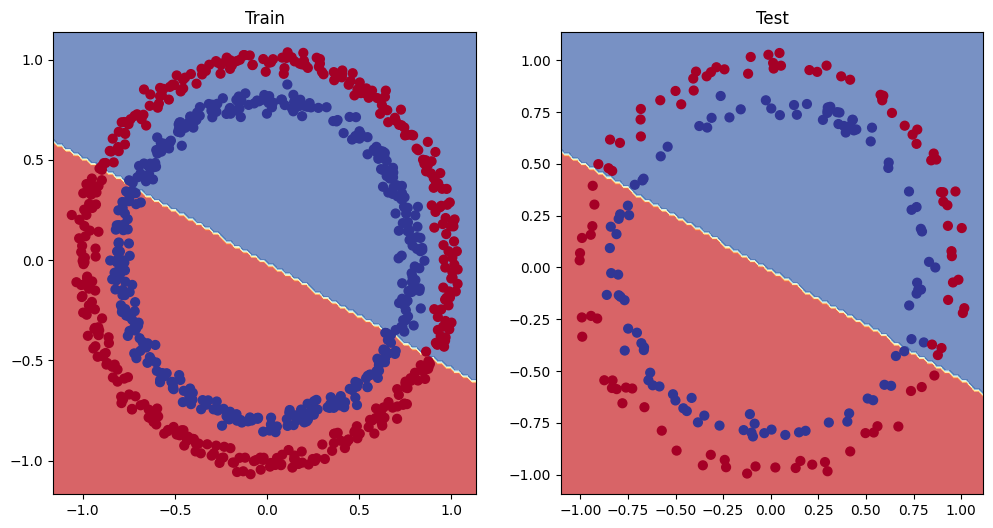

In [31]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

# 5. Improve the Model (CircleModelV1)

### 5.1. Build the Model (CircleModelV1)

In [32]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10) # extra layer
        self.layer_3 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x): # note: always make sure forward is spelt correctly!
        # Creating a model like this is the same as below, though below
        # generally benefits from speedups where possible.
        # z = self.layer_1(x)
        # z = self.layer_2(z)
        # z = self.layer_3(z)
        # return z
        return self.layer_3(self.layer_2(self.layer_1(x)))

model_1 = CircleModelV1().to(device)
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

### 5.2. Loss Function and Optimizer (CircleModelV1)

In [33]:
# loss_fn = nn.BCELoss() # Requires sigmoid on input
loss_fn = nn.BCEWithLogitsLoss() # Does not require sigmoid on input
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)

### 5.3. Build Training and Testing Loop
#### Note: Longer Training Loop (epochs=1000)

In [ ]:
torch.manual_seed(42)

epochs = 1000 # Train for longer

# Put data to target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Table Header
print("=" * 65)
print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Train Acc':^11} | {'Test Loss':^11} | {'Test Acc':^10}")
print("=" * 65)

for epoch in range(epochs):
    ### Training
    # 1. Forward pass
    train_logits = model_1(X_train).squeeze()
    train_pred = torch.round(torch.sigmoid(train_logits)) # logits -> prediction probabilities -> prediction labels

    # 2. Calculate loss/accuracy
    loss = loss_fn(train_logits, y_train) # BCEWithLogits()
    acc = accuracy_fn(y_true=y_train,
                      y_pred=train_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_1.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epoch % 10 == 0 or epoch == epochs - 1:
        print(f"{epoch:^7} | {loss:^12.5f} | {acc:^10.2f}% | {test_loss:^11.5f} | {test_acc:^9.2f}%")



 Epoch  |  Train Loss  |  Train Acc  |  Test Loss  |  Test Acc 
   0    |   4.12940    |   50.00   % |   3.17704   |   50.00  %
  10    |   0.91546    |   50.00   % |   0.87499   |   50.00  %
  20    |   0.73541    |   50.00   % |   0.73003   |   50.00  %
  30    |   0.70590    |   50.00   % |   0.70442   |   50.00  %
  40    |   0.69842    |   41.25   % |   0.69776   |   46.00  %
  50    |   0.69604    |   47.62   % |   0.69564   |   46.00  %
  60    |   0.69506    |   49.75   % |   0.69480   |   45.00  %
  70    |   0.69453    |   49.50   % |   0.69440   |   46.50  %
  80    |   0.69418    |   50.12   % |   0.69417   |   46.50  %
  90    |   0.69393    |   50.25   % |   0.69403   |   46.50  %
  100   |   0.69374    |   50.38   % |   0.69394   |   46.00  %
  110   |   0.69359    |   50.25   % |   0.69389   |   48.00  %
  120   |   0.69347    |   49.50   % |   0.69387   |   48.50  %
  130   |   0.69338    |   49.62   % |   0.69386   |   49.50  %
  140   |   0.69330    |   49.38   % |  

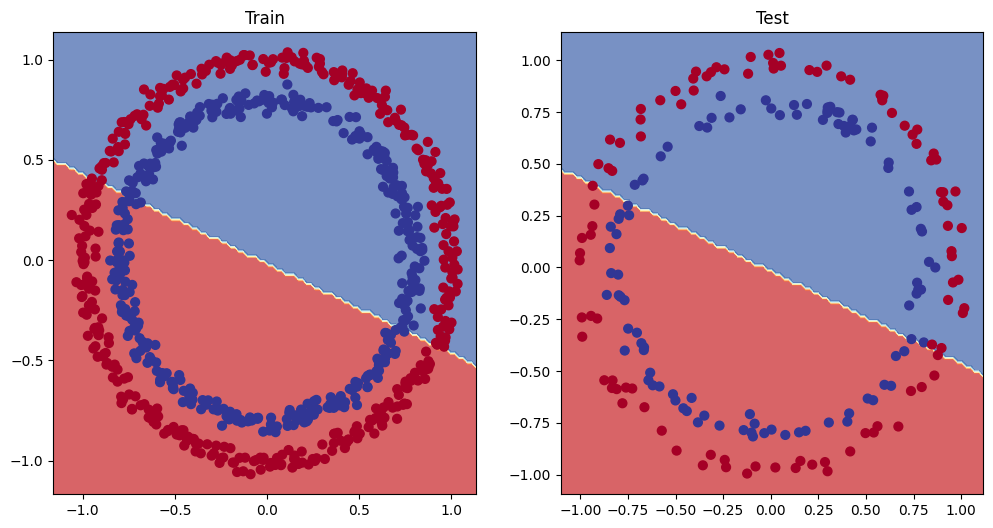

In [46]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)